# assignment_1.ipynb

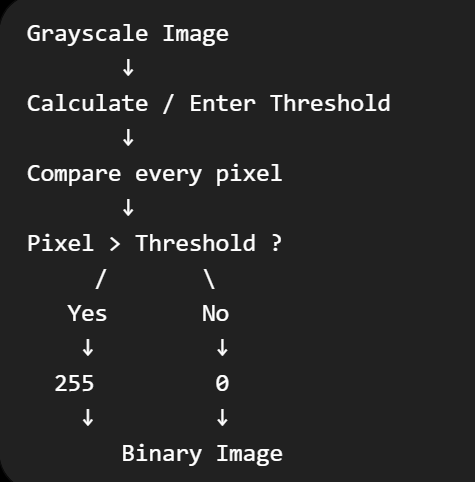

What exactly is a grayscale image?

 A grayscale image has only one intensity value per pixel.

| Intensity | Meaning     |
| --------: | ----------- |
|         0 | Black       |
|        50 | Dark gray   |
|       127 | Medium gray |
|       200 | Light gray  |
|       255 | White       |



What is a binary image?

A binary image has only two possible values:

0    → Black

255  → White

Why do we need thresholding?

Thresholding is a technique used to convert a grayscale image into a binary image by comparing each pixel intensity with a threshold value.


        Object
          ↓
     █████████
     █████████
-------------------
     Background

The object may have brighter pixels than the background.

Thresholding lets us separate them:

Original grayscale

        ↓
Thresholding

        ↓
Object vs Background

That's why thresholding is useful in:

Image segmentation

Object detection

Document processing

Character recognition

Medical images

Computer vision

Mean intensity

Mean = sum of all pixel intensities​/ no of pixels




Example ->

image ->

10  20  30

40  50  60

70  80  90

Threshold = 50

Pixel >= 50 → 255

Pixel < 50  → 0

Result:

0    0    0

0   255  255

255 255  255


In [ ]:
from PIL import Image

In [ ]:
img = Image.open("IRONMAN Poster Design.jpg").convert("L") # "L" means grayscale.

In [ ]:
width, height = img.size

pixels = list(img.getdata())

image = []

for i in range(height):
    row = []

    for j in range(width):
        row.append(pixels[i * width + j])

    image.append(row)

In [ ]:
image

In [ ]:
total = 0
count = 0

for row in image:
    for pixel in row:
        total = total + pixel
        count = count + 1

threshold = total / count

print("Mean intensity =", threshold)

In [ ]:
binary = []

for row in image:
    new_row = []

    for pixel in row:
        if pixel >= threshold:
            new_row.append(255)
        else:
            new_row.append(0)

    binary.append(new_row)

In [ ]:
binary_pixels = []

for row in binary:
    for pixel in row:
        binary_pixels.append(pixel)

In [ ]:
binary_image = Image.new("L", (width, height))

binary_image.putdata(binary_pixels)

display(binary_image)

Case 2 — User enters threshold

In [ ]:
threshold = int(input("Enter threshold value (0-255): "))

binary = []

for row in image:
    new_row = []

    for pixel in row:
        if pixel >= threshold:
            new_row.append(255)
        else:
            new_row.append(0)

    binary.append(new_row)

binary_pixels = []

for row in binary:
    for pixel in row:
        binary_pixels.append(pixel)

binary_image = Image.new("L", (width, height))
binary_image.putdata(binary_pixels)

print("Threshold =", threshold)

display(binary_image)

In [ ]:
# NOW DOING IT BY USING OPENCV

In [ ]:
import cv2

In [ ]:
print(cv2.__version__)

In [ ]:
img = cv2.imread("MF.jpg")

In [ ]:
# directly read it as grey scale image
img = cv2.imread("MF.jpg", cv2.IMREAD_GRAYSCALE)

In [ ]:
print(img.shape) # so image as 1200 rows and 675 columns so total 1200*675 = 8,10,000 pixels

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(img, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

In [ ]:
threshold = img.mean()

In [ ]:
print("Mean intensity =", threshold)

In [ ]:
threshold = int(img.mean())

In [ ]:
print("Threshold =", threshold)

In [ ]:
ret, binary = cv2.threshold(
    img,
    threshold,
    255,
    cv2.THRESH_BINARY
)
# ret -> the threshold that opencv used
# binary -> the resulting threshold image

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

In [ ]:
# Case 2 taking threshold value from the user

In [ ]:
threshold = int(input("Enter threshold value (0-255): "))

_, binary = cv2.threshold(
    img,
    threshold,
    255,
    cv2.THRESH_BINARY
)

print("Threshold =", threshold)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

# assignment_2.ipynb

RGB (Color) Image → Grayscale Image

Why do we convert RGB to grayscale?

-> RGB = R + G + B

-> Gray scale is single value

RGB pixel
(100, 50, 20)

      ↓
Grayscale

     56

**CASE 1 — Mean average of three planes**



gray = ( R + G + B )/ 3

so pixel(0,0):

gray = (100+50+20)/3 = 56.67 ~ 57

so gray[0] = 57

so on we can find all others

**CASE 2 — Weighted average**

Gray=R×WR​+G×WG​+B×WB​

R = 100
, G = 50
, B = 20

WR = 0.7
, WG = 0.2
, WB = 0.1


Gray=(100×0.7)+(50×0.2)+(20×0.1)

Gray=70+10+2

Gray=82

In [ ]:
# FIRST BY DOING USING BASIC PYTHON

In [ ]:
# MEAN Avg of three panels

In [ ]:
from PIL import Image
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = Image.open(filename).convert("RGB")

width, height = img.size

pixels = list(img.getdata())

grayscale = []

index = 0

for i in range(height):
    row = []

    for j in range(width):

        r, g, b = pixels[index]

        gray = (r + g + b) / 3

        row.append(int(gray))

        index = index + 1

    grayscale.append(row)

gray_pixels = []

for row in grayscale:
    for pixel in row:
        gray_pixels.append(pixel)

gray_image = Image.new("L", (width, height))
gray_image.putdata(gray_pixels)

display(img)
display(gray_image)

In [ ]:
# Weighted Avg of three panels

In [ ]:
wr = float(input("Enter weight for R: "))
wg = float(input("Enter weight for G: "))
wb = float(input("Enter weight for B: "))

if not (0 <= wr <= 1 and 0 <= wg <= 1 and 0 <= wb <= 1):
    print("Invalid weights")

elif abs(wr + wg + wb - 1) > 0.0001:
    print("Sum of weights must be equal to 1")

else:

    grayscale = []

    index = 0

    for i in range(height):
        row = []

        for j in range(width):

            r, g, b = pixels[index]

            gray = (r * wr) + (g * wg) + (b * wb)

            row.append(int(gray))

            index = index + 1

        grayscale.append(row)

    gray_pixels = []

    for row in grayscale:
        for pixel in row:
            gray_pixels.append(pixel)

    gray_image = Image.new("L", (width, height))
    gray_image.putdata(gray_pixels)

    display(img)
    display(gray_image)

In [ ]:
# NOW DOING IT BY OPENCV

In [ ]:
# #OpenCV reads color images as BGR, not RGB
# Channel 0 → Blue
# Channel 1 → Green
# # Channel 2 → Red

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

img = cv2.imread(filename)

b, g, r = cv2.split(img)

gray = (r.astype(float) + g.astype(float) + b.astype(float)) / 3

gray = gray.astype(np.uint8)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

In [ ]:
# now by weighted mean method

In [ ]:
wr = float(input("Enter weight for R: "))
wg = float(input("Enter weight for G: "))
wb = float(input("Enter weight for B: "))

if not (0 <= wr <= 1 and 0 <= wg <= 1 and 0 <= wb <= 1):

    print("Invalid weights")

elif abs(wr + wg + wb - 1) > 0.0001:

    print("Sum of weights must be equal to 1")

else:

    gray = (
        r.astype(float) * wr +
        g.astype(float) * wg +
        b.astype(float) * wb
    )

    gray = gray.astype(np.uint8)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original RGB Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Weighted Grayscale Image")
    plt.axis("off")

    plt.show()

# assignment_3.ipynb

What is image padding?

-Suppose our original grayscale image is:

100 120 150

80  90  130

60  70  110

-If the user says:

Border width = 1 pixel

Border color = 255

-We add one row/column of pixels around the image:

255 255 255 255 255

255 100 120 150 255

255 80  90  130 255

255 60  70  110 255

255 255 255 255 255

-So the image becomes larger.

If original dimensions are:

New height = H + 2b

New width  = W + 2b



Why do we need padding?

Padding is commonly used in image processing because operations such as:

filtering ,
convolution,
edge detection,
morphological operations,

often need pixels around the boundary of an image.

Image Complement

For a binary image:

0 → 255

255 → 0

Grayscale complement

For an 8-bit grayscale image:

0 → 255

1 → 254

2 → 253

...

128 → 127

...

254 → 1

255 → 0

g(x,y)=255−f(x,y)



In [ ]:
# FIRST USING SIMPLE PYTHON CODE

# Q(1)

In [ ]:
!pip install pillow

from PIL import Image

# --------------------------------
# Function to add border
# --------------------------------

def add_border(image, border_width, border_color):

    width, height = image.size

    # New image dimensions
    new_width = width + 2 * border_width
    new_height = height + 2 * border_width

    # Create new image filled with border color
    padded_image = Image.new(
        image.mode,
        (new_width, new_height),
        border_color
    )

    # Copy original image into the center
    for y in range(height):
        for x in range(width):

            pixel = image.getpixel((x, y))

            padded_image.putpixel(
                (x + border_width, y + border_width),
                pixel
            )

    return padded_image


# --------------------------------
# Main program
# --------------------------------

# Using a default image path for demonstration purposes as 'abc' was not found.
# You can change this back to input("Enter image path: ") to prompt for a file.
image_path = "/content/abc.jpg" # Changed from input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

# Using default values for border_width and border_color for demonstration.
# You can change these back to int(input(...)) to prompt for values.
border_width = 1 # Changed from int(input("Enter border width: "))
border_color = 255 # Changed from int(input("Enter border color (0-255): "))

result = add_border(
    image,
    border_width,
    border_color
)

result.save("border_output.png")

result.show()

print("Border added successfully.")
print("Output saved as border_output.png")

In [ ]:
# Q(2)

from PIL import Image

# --------------------------------
# Function for image complement
# --------------------------------

def image_complement(image):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            pixel = image.getpixel((x, y))

            new_pixel = 255 - pixel

            result.putpixel(
                (x, y),
                new_pixel
            )

    return result


# --------------------------------
# Main program
# --------------------------------

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert image to grayscale
image = image.convert("L")

result = image_complement(image)

result.save("complement_output.png")

result.show()

print("Image complement generated successfully.")
print("Output saved as complement_output.png")

In [ ]:
# NOW USING OPEN CV

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

# Read image
image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

# Check whether image was loaded
if image is None:
    print("Error: Image not found.")
    exit()

# Take input
border_width = int(input("Enter border width: "))
border_color = int(input("Enter border color (0-255): "))

# Add border
result = cv2.copyMakeBorder(
    image,
    border_width,
    border_width,
    border_width,
    border_width,
    cv2.BORDER_CONSTANT,
    value=border_color
)

# Display
cv2_imshow(image)
cv2_imshow(result)

# Save
cv2.imwrite("opencv_border_output.png", result)

# cv2.waitKey(0) # Not needed with cv2_imshow
# cv2.destroyAllWindows() # Not needed with cv2_imshow

print("Border added successfully.")

In [ ]:
# Q(2)
import cv2
from google.colab.patches import cv2_imshow

# Read image
image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()

# Find complement
result = cv2.bitwise_not(image)

# Display
cv2_imshow(image)
cv2_imshow(result)

# Save
cv2.imwrite("opencv_complement_output.png", result)

# cv2.waitKey(0) # Not needed with cv2_imshow
# cv2.destroyAllWindows() # Not needed with cv2_imshow

print("Image complement generated successfully.")

# assignment_4.ipynb

What is Image Enhancement?

Image enhancement means modifying an image so that important features become easier to see.

1. Log Transformation

s = c log(1+r)

r = input pixel intensity

s = output pixel intensity

c = constant

log = logarithm

Why use log transformation?

The logarithm has an interesting property:

Small intensity values get expanded

while

Large intensity values get compressed.




In [ ]:
from PIL import Image
import math


# ==========================================
# LOG TRANSFORMATION
# ==========================================

def log_transform(image):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            r = image.getpixel((x, y))

            # Log transformation
            s = math.log(1 + r)

            # Normalize to 0-255
            s = (s / math.log(256)) * 255

            result.putpixel((x, y), int(s))

    return result


# ==========================================
# MAIN PROGRAM
# ==========================================

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

result = log_transform(image)

result.save("log_output.png")

image.show()
result.show()

print("Log transformation completed.")
print("Output saved as log_output.png")

2. Power-Law / Gamma Transformation

The formula is:

$$ s=cr^\gamma $$

Since:

$$ c=1 $$

we get:

$$ \boxed{s=r^\gamma} $$

where:

r = input pixel

s = output pixel

γ = gamma value

rn = r/255

Then apply gamma:

$$ s_n=r_n^\gamma $$

Then convert back:

$$ \boxed{s=255(r/255)^\gamma} $$

This is the practical formula we'll use.

What does Gamma do?

Gamma < 1  -> The image generally becomes brighter.

Gamma = 1 -> No change

Gamma > 1  -> The image generally becomes darker.

In [ ]:
from PIL import Image


# ==========================================
# POWER LAW / GAMMA TRANSFORMATION
# ==========================================

def gamma_transform(image, gamma):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            r = image.getpixel((x, y))

            # Normalize pixel to 0-1
            normalized = r / 255.0

            # Gamma transformation
            s = normalized ** gamma

            # Convert back to 0-255
            s = s * 255

            result.putpixel((x, y), int(s))

    return result


# ==========================================
# MAIN PROGRAM
# ==========================================

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

gamma = float(input("Enter gamma value: "))

result = gamma_transform(image, gamma)

result.save("gamma_output.png")

image.show()
result.show()

print("Gamma transformation completed.")
print("Output saved as gamma_output.png")

3. Intensity Level Transformation / Contrast Stretching


What is contrast stretching?

80 → 120

That means the image has relatively limited contrast.

We want to stretch it to:
50 → 150

so :

80 → 50

120 → 150

and values between them are mapped proportionally.


Input range:
r1 → r2

Output range:
s1 → s2

Then for an input pixel r:

$$ \boxed{ s=s_1+ \frac{(r-r_1)(s_2-s_1)} {(r_2-r_1)} } $$

This is basically the equation of a straight line



In [ ]:
from PIL import Image


# ==========================================
# CONTRAST STRETCHING
# ==========================================

def contrast_stretch(image, r1, r2, s1, s2):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            r = image.getpixel((x, y))

            # Pixel below input range
            if r < r1:
                s = s1

            # Pixel above input range
            elif r > r2:
                s = s2

            # Pixel inside input range
            else:
                s = s1 + ((r - r1) * (s2 - s1)) / (r2 - r1)

            result.putpixel((x, y), int(s))

    return result


# ==========================================
# MAIN PROGRAM
# ==========================================

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

# Input range
r1 = int(input("Enter input lower intensity: "))
r2 = int(input("Enter input upper intensity: "))

# Desired output range
s1 = int(input("Enter output lower intensity: "))
s2 = int(input("Enter output upper intensity: "))

result = contrast_stretch(
    image,
    r1,
    r2,
    s1,
    s2
)

result.save("contrast_output.png")

image.show()
result.show()

print("Contrast stretching completed.")
print("Output saved as contrast_output.png")

In [ ]:
# NOW USING OPENCV

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()


# Convert pixels to float
image_float = image.astype(np.float32)

# Log transformation
result = np.log1p(image_float)

# Normalize to 0-255
result = cv2.normalize(
    result,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

result = result.astype(np.uint8)


cv2_imshow(image)
cv2_imshow(result)

cv2.imwrite(
    "opencv_log_output.png",
    result
)

cv2.waitKey(0)
cv2.destroyAllWindows()

print("Log transformation completed.")

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()


gamma = float(input("Enter gamma value: "))


# Normalize image
normalized = image / 255.0

# Gamma transformation
result = np.power(normalized, gamma)

# Convert back to 0-255
result = result * 255

result = result.astype(np.uint8)


cv2_imshow(image)
cv2_imshow(result)

cv2.imwrite(
    "opencv_gamma_output.png",
    result
)

cv2.waitKey(0)
cv2.destroyAllWindows()

print("Gamma transformation completed.")

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()


# Input range
r1 = int(input("Enter input lower intensity: "))
r2 = int(input("Enter input upper intensity: "))

# Output range
s1 = int(input("Enter output lower intensity: "))
s2 = int(input("Enter output upper intensity: "))


result = np.zeros_like(image)


for y in range(image.shape[0]):
    for x in range(image.shape[1]):

        r = int(image[y, x])

        if r < r1:
            s = s1

        elif r > r2:
            s = s2

        else:
            s = s1 + ((r - r1) * (s2 - s1)) / (r2 - r1)

        result[y, x] = int(s)


cv2_imshow(image)
cv2_imshow(result)

cv2.imwrite(
    "opencv_contrast_output.png",
    result
)

cv2.waitKey(0)
cv2.destroyAllWindows()

print("Contrast stretching completed.")

# assignment_6.ipynb

1. Image smoothing — basic concept
Image smoothing reduces noise and small intensity variations in an image. It works by replacing each pixel with a value calculated from its neighboring pixels.

For example, instead of keeping one pixel's intensity as 200, we might replace it with the average of the surrounding pixels.
The three filters









1. Averaging filter (unweighted)

All pixels in the filter window receive equal importance. For a \(3\times3\) filter, add the nine pixel values and divide by 9.












2. Weighted filter

Neighboring pixels receive different weights. Your assignment specifies \(h(x,y)=\max(|x|,|y|)\). We'll implement this formula exactly, while handling its zero-weight center separately.












3. Gaussian filter

Nearby pixels receive higher weights than distant pixels, following a Gaussian distribution. Sigma (\(\sigma\)) controls the spread of the weights.



Padding methods
- Zero padding: Pixels outside the image are treated as 0.
- Replication padding: The border pixel values are repeated beyond the image boundary.

In [ ]:
# Python code — without OpenCV

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read grayscale image
img = np.array(
    Image.open("abc.jpg").convert("L"),
    dtype=np.float64
)

# Take input from user
size = int(input("Enter filter size (odd number): "))
padding_type = input(
    "Enter padding (zero / replication): "
).lower()

if size <= 0 or size % 2 == 0:
    raise ValueError("Filter size must be a positive odd number.")

if padding_type not in ("zero", "replication"):
    raise ValueError("Choose zero or replication padding.")

sigma = float(input("Enter Gaussian sigma (> 0): "))

if sigma <= 0:
    raise ValueError("Sigma must be greater than zero.")

# Create filter weights
r = size // 2
coords = np.arange(-r, r + 1)
X, Y = np.meshgrid(coords, coords)

# 1. Unweighted averaging filter
average_kernel = np.ones((size, size)) / (size * size)

# 2. Weighted filter: h(x,y) = max(|x|, |y|)
weighted_kernel = np.maximum(np.abs(X), np.abs(Y)).astype(float)

# Normalize weights; center has zero weight
weighted_kernel /= weighted_kernel.sum()

# 3. Gaussian filter
gaussian_kernel = np.exp(
    -(X**2 + Y**2) / (2 * sigma**2)
)
gaussian_kernel /= gaussian_kernel.sum()


def apply_filter(image, kernel, padding_type):
    r = kernel.shape[0] // 2

    if padding_type == "zero":
        padded = np.pad(
            image, ((r, r), (r, r)),
            mode="constant", constant_values=0
        )
    else:
        padded = np.pad(
            image, ((r, r), (r, r)),
            mode="edge"
        )

    output = np.zeros_like(image, dtype=float)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i + 2*r + 1,
                            j:j + 2*r + 1]

            output[i, j] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)


# Apply all three filters
average_img = apply_filter(
    img, average_kernel, padding_type
)

weighted_img = apply_filter(
    img, weighted_kernel, padding_type
)

gaussian_img = apply_filter(
    img, gaussian_kernel, padding_type
)

# Display results
images = [
    (img, "Original"),
    (average_img, "Averaging Filter"),
    (weighted_img, "Weighted Filter"),
    (gaussian_img, "Gaussian Filter")
]

plt.figure(figsize=(12, 8))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# OpenCV code

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check the image path.")

# User inputs
size = int(input("Enter filter size (odd number): "))
padding_type = input(
    "Enter padding (zero / replication): "
).lower()
sigma = float(input("Enter Gaussian sigma (> 0): "))

if size <= 0 or size % 2 == 0:
    raise ValueError("Filter size must be a positive odd number.")

if padding_type not in ("zero", "replication"):
    raise ValueError("Choose zero or replication padding.")

if sigma <= 0:
    raise ValueError("Sigma must be greater than zero.")

# Choose border handling
if padding_type == "zero":
    border_type = cv2.BORDER_CONSTANT
else:
    border_type = cv2.BORDER_REPLICATE

# 1. Averaging filter
average_img = cv2.blur(
    img, (size, size),
    borderType=border_type
)

# 2. Weighted filter: h(x,y) = max(|x|, |y|)
r = size // 2
coords = np.arange(-r, r + 1)
X, Y = np.meshgrid(coords, coords)

weighted_kernel = np.maximum(
    np.abs(X), np.abs(Y)
).astype(np.float32)

weighted_kernel /= weighted_kernel.sum()

weighted_img = cv2.filter2D(
    img, -1, weighted_kernel,
    borderType=border_type
)

# 3. Gaussian filter
gaussian_img = cv2.GaussianBlur(
    img, (size, size), sigmaX=sigma,
    borderType=border_type
)

# Display results
images = [
    (img, "Original"),
    (average_img, "Averaging Filter"),
    (weighted_img, "Weighted Filter"),
    (gaussian_img, "Gaussian Filter")
]

plt.figure(figsize=(12, 8))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(2, 2, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# assignment_7.ipynb

1. Concept of image sharpening
Image sharpening makes edges and fine details in an image more prominent.









1. Laplacian filter

Detects rapid changes in intensity using second-order derivatives. We combine the Laplacian response with the original image to enhance edges.












2. Sobel and Canny
- Sobel: Detects intensity changes in horizontal and vertical directions.
- Canny: Detects edges using smoothing, gradients, non-maximum suppression, and thresholding. Canny produces an edge map, not a sharpened image by itself, so we'll use its edges to enhance the original image.












3. Unsharp masking

First blur the image, then subtract the blurred image from the original to obtain a detail mask. Add this mask back to the original image to sharpen it.

In [ ]:
# Python code — without OpenCV
%pip install numpy pillow matplotlib scipy scikit-image
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import convolve2d
from scipy.ndimage import gaussian_filter
from skimage.feature import canny

# Read grayscale image
img = np.array(
    Image.open("abc.jpg").convert("L"),
    dtype=np.float64
)

# 1. LAPLACIAN SHARPENING
laplacian_kernel = np.array([
    [0, -1,  0],
    [-1, 4, -1],
    [0, -1,  0]
], dtype=float)

laplacian = convolve2d(
    img, laplacian_kernel,
    mode="same", boundary="symm"
)

laplacian_sharp = np.clip(
    img + laplacian, 0, 255
).astype(np.uint8)


# 2. SOBEL SHARPENING
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

gx = convolve2d(
    img, sobel_x, mode="same", boundary="symm"
)
gy = convolve2d(
    img, sobel_y, mode="same", boundary="symm"
)

gradient = np.sqrt(gx**2 + gy**2)

# Normalize gradient for display
sobel_edges = (
    gradient / (gradient.max() + 1e-8) * 255
).astype(np.uint8)

# Use gradient as a detail mask for sharpening
sobel_sharp = np.clip(
    img + 0.5 * gradient, 0, 255
).astype(np.uint8)


# CANNY EDGE DETECTOR
# Returns a binary edge map
canny_edges = canny(
    img / 255.0,
    sigma=1.0,
    low_threshold=0.1,
    high_threshold=0.2
)

canny_edges = (canny_edges * 255).astype(np.uint8)

# Enhance the original using Canny edges
canny_sharp = np.clip(
    img + 0.5 * canny_edges, 0, 255
).astype(np.uint8)


# 3. UNSHARP MASKING
# Required Gaussian blur: size 5x5, sigma = 3
# A 5x5 Gaussian kernel is constructed manually.
coords = np.arange(-2, 3)
X, Y = np.meshgrid(coords, coords)

sigma = 3.0

gaussian_kernel = np.exp(
    -(X**2 + Y**2) / (2 * sigma**2)
)
gaussian_kernel /= gaussian_kernel.sum()

blurred = convolve2d(
    img, gaussian_kernel,
    mode="same", boundary="symm"
)

mask = img - blurred

unsharp = np.clip(
    img + mask, 0, 255
).astype(np.uint8)


# DISPLAY RESULTS
images = [
    (img, "Original Image"),
    (laplacian_sharp, "Laplacian Sharpening"),
    (sobel_edges, "Sobel Edge Map"),
    (sobel_sharp, "Sobel Sharpening"),
    (canny_edges, "Canny Edge Map"),
    (canny_sharp, "Canny-Based Sharpening"),
    (unsharp, "Unsharp Masking")
]

plt.figure(figsize=(14, 10))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(3, 3, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# OpenCV code

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check the image path.")

# Convert to float for sharpening calculations
img_float = img.astype(np.float32)


# 1. LAPLACIAN SHARPENING
laplacian = cv2.Laplacian(
    img_float, cv2.CV_32F, ksize=1
)

laplacian_sharp = np.clip(
    img_float + laplacian, 0, 255
).astype(np.uint8)


# 2. SOBEL SHARPENING
gx = cv2.Sobel(
    img_float, cv2.CV_32F, 1, 0, ksize=3
)
gy = cv2.Sobel(
    img_float, cv2.CV_32F, 0, 1, ksize=3
)

gradient = cv2.magnitude(gx, gy)

sobel_edges = cv2.normalize(
    gradient, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

sobel_sharp = np.clip(
    img_float + 0.5 * gradient, 0, 255
).astype(np.uint8)


# CANNY EDGE DETECTION
canny_edges = cv2.Canny(
    img, threshold1=100, threshold2=200
)

# Use detected edges to enhance the original
canny_sharp = np.clip(
    img_float + 0.5 * canny_edges.astype(np.float32),
    0, 255
).astype(np.uint8)


# 3. UNSHARP MASKING
# Required kernel size = 5x5 and sigma = 3
blurred = cv2.GaussianBlur(
    img, (5, 5), sigmaX=3, sigmaY=3
)

mask = img_float - blurred.astype(np.float32)

unsharp = np.clip(
    img_float + mask, 0, 255
).astype(np.uint8)


# DISPLAY ALL RESULTS
images = [
    (img, "Original Image"),
    (laplacian_sharp, "Laplacian Sharpening"),
    (sobel_edges, "Sobel Edge Map"),
    (sobel_sharp, "Sobel Sharpening"),
    (canny_edges, "Canny Edge Map"),
    (canny_sharp, "Canny-Based Sharpening"),
    (unsharp, "Unsharp Masking")
]

plt.figure(figsize=(14, 10))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(3, 3, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# assignment_8.ipynb

1. Concept: Image noise
Noise means random variations in pixel intensity. We add noise to an image to simulate disturbances that can occur during image capture or transmission.
The five noise distributions

1. Uniform noise

Every value within a specified interval is equally likely. Its histogram ideally looks flat.




2. Gaussian noise

Values near the mean occur more frequently than extreme values. Its histogram resembles a bell curve.




3. Erlang noise

A positive-valued distribution determined by a shape parameter \(k\) and rate parameter \(\lambda\). It is a special case of the Gamma distribution when \(k\) is a positive integer.




4. Exponential noise

Positive values are generated, with small values occurring more frequently than large values. Its histogram generally decreases from left to right.




5. Rayleigh noise

A positive-valued distribution that starts near zero, rises to a peak, and then decreases.

In [ ]:
# python code - without opencv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read grayscale image
img = np.array(
    Image.open("abc.jpg").convert("L"),
    dtype=np.float64
)

rng = np.random.default_rng(42)
shape = img.shape

# Parameters
a, b = -20, 20            # Uniform limits
mu, sigma_g = 0, 10       # Gaussian mean and standard deviation
k, rate = 3, 0.2          # Erlang shape and rate
rate_e = 0.2              # Exponential rate
sigma_r = 10              # Rayleigh scale


# 1. UNIFORM NOISE
u = rng.random(shape)
uniform_manual = a + (b - a) * u
uniform_builtin = rng.uniform(a, b, shape)


# 2. GAUSSIAN NOISE (Box-Muller method)
u1 = np.maximum(rng.random(shape), 1e-12)
u2 = rng.random(shape)

z = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_manual = mu + sigma_g * z
gaussian_builtin = rng.normal(mu, sigma_g, shape)


# 3. ERLANG NOISE (sum of k exponential variables)
u = np.maximum(rng.random((k, *shape)), 1e-12)
erlang_manual = -np.sum(np.log(u), axis=0) / rate
erlang_builtin = rng.gamma(
    shape=k, scale=1 / rate, size=shape
)


# 4. EXPONENTIAL NOISE (inverse CDF)
u = np.maximum(rng.random(shape), 1e-12)
exponential_manual = -np.log(u) / rate_e
exponential_builtin = rng.exponential(
    scale=1 / rate_e, size=shape
)


# 5. RAYLEIGH NOISE (inverse CDF)
u = np.maximum(rng.random(shape), 1e-12)
rayleigh_manual = sigma_r * np.sqrt(-2 * np.log(u))
rayleigh_builtin = rng.rayleigh(
    scale=sigma_r, size=shape
)


# Collect results
results = [
    ("Uniform", uniform_manual, uniform_builtin),
    ("Gaussian", gaussian_manual, gaussian_builtin),
    ("Erlang", erlang_manual, erlang_builtin),
    ("Exponential", exponential_manual, exponential_builtin),
    ("Rayleigh", rayleigh_manual, rayleigh_builtin)
]


# Display noisy images and histograms
fig, axes = plt.subplots(5, 3, figsize=(13, 19))

for i, (name, manual, builtin) in enumerate(results):

    # Add noise to image and clip intensities to [0, 255]
    noisy_manual = np.clip(img + manual, 0, 255)
    noisy_builtin = np.clip(img + builtin, 0, 255)

    axes[i, 0].imshow(
        noisy_manual, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title(name + " - Manual")

    axes[i, 1].imshow(
        noisy_builtin, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title(name + " - Built-in")

    # Compare distributions of generated noise itself
    axes[i, 2].hist(
        manual.ravel(), bins=60, density=True,
        alpha=0.6, label="Manual"
    )
    axes[i, 2].hist(
        builtin.ravel(), bins=60, density=True,
        alpha=0.5, label="Built-in"
    )
    axes[i, 2].set_title(name + " - Noise Histogram")
    axes[i, 2].legend()

    for j in range(3):
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

plt.tight_layout()
plt.show()

In [ ]:
# openCV
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image using OpenCV
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check the image path.")

img = img.astype(np.float64)
shape = img.shape
rng = np.random.default_rng(42)

# Parameters
a, b = -20, 20
mu, sigma_g = 0, 10
k, rate = 3, 0.2
rate_e = 0.2
sigma_r = 10

# 1. UNIFORM NOISE
u = rng.random(shape)
uniform_manual = a + (b - a) * u
uniform_builtin = rng.uniform(a, b, shape)

# 2. GAUSSIAN NOISE
u1 = np.maximum(rng.random(shape), 1e-12)
u2 = rng.random(shape)

z = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_manual = mu + sigma_g * z
gaussian_builtin = rng.normal(mu, sigma_g, shape)

# 3. ERLANG NOISE
u = np.maximum(rng.random((k, *shape)), 1e-12)
erlang_manual = -np.sum(np.log(u), axis=0) / rate
erlang_builtin = rng.gamma(k, 1 / rate, shape)

# 4. EXPONENTIAL NOISE
u = np.maximum(rng.random(shape), 1e-12)
exponential_manual = -np.log(u) / rate_e
exponential_builtin = rng.exponential(1 / rate_e, shape)

# 5. RAYLEIGH NOISE
u = np.maximum(rng.random(shape), 1e-12)
rayleigh_manual = sigma_r * np.sqrt(-2 * np.log(u))
rayleigh_builtin = rng.rayleigh(sigma_r, shape)

results = [
    ("Uniform", uniform_manual, uniform_builtin),
    ("Gaussian", gaussian_manual, gaussian_builtin),
    ("Erlang", erlang_manual, erlang_builtin),
    ("Exponential", exponential_manual, exponential_builtin),
    ("Rayleigh", rayleigh_manual, rayleigh_builtin)
]

# Display images and compare histograms
fig, axes = plt.subplots(5, 3, figsize=(13, 19))

for i, (name, manual, builtin) in enumerate(results):

    # Create noisy images
    noisy_manual = np.clip(img + manual, 0, 255).astype(np.uint8)
    noisy_builtin = np.clip(img + builtin, 0, 255).astype(np.uint8)

    axes[i, 0].imshow(
        noisy_manual, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 0].set_title(name + " - Manual")

    axes[i, 1].imshow(
        noisy_builtin, cmap="gray", vmin=0, vmax=255
    )
    axes[i, 1].set_title(name + " - Built-in")

    # Histograms of noise values
    axes[i, 2].hist(
        manual.ravel(), bins=60, density=True,
        alpha=0.6, label="Manual"
    )
    axes[i, 2].hist(
        builtin.ravel(), bins=60, density=True,
        alpha=0.5, label="Built-in"
    )
    axes[i, 2].set_title(name + " - Noise Histogram")
    axes[i, 2].legend()

    for j in range(3):
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

plt.tight_layout()
plt.show()

# assignment_9.ipynb

Implement Local Binary Pattern (LBP) on a grayscale image.

LBP is a technique used in image processing to identify texture patterns.

How it works:
1. Take a 3×3 pixel window.
2. Consider the center pixel.
3. Compare all 8 neighbouring pixels with the center.
4. If a neighbour is greater than or equal to the center, assign 1.
5. Otherwise, assign 0.
6. Convert the 8 binary values into a decimal number.



Image denoising
Image denoising means removing unwanted noise from an image while preserving important details.

Gaussian noise: Random noise that follows a Gaussian (normal) distribution. It makes the image look grainy.

Speckle noise: Multiplicative noise that creates a grainy or spotted appearance.

Four filters
Filter      	Basic working

Wiener ---      Uses local mean and variance to reduce noise.


Median  ---- 	Replaces a pixel with the median of neighbouring pixels.

Gaussian ----	Uses a weighted average of neighbouring pixels.

Bilateral ---- 	Smooths noise while preserving edges.

In [ ]:
pip install numpy pillow matplotlib

In [ ]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(Image.open("input.jpg").convert("L"))

# Create output image
lbp = np.zeros((img.shape[0]-2, img.shape[1]-2), dtype=np.uint8)

# Apply Local Binary Pattern
for i in range(1, img.shape[0]-1):
    for j in range(1, img.shape[1]-1):

        center = img[i, j]
        binary = 0

        neighbors = [
            img[i-1, j-1], img[i-1, j],
            img[i-1, j+1], img[i, j+1],
            img[i+1, j+1], img[i+1, j],
            img[i+1, j-1], img[i, j-1]
        ]

        for k in range(8):
            if neighbors[k] >= center:
                binary += (1 << (7-k))

        lbp[i-1, j-1] = binary

# Display results
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("LBP Image")
plt.axis("off")

plt.show()


In [ ]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(Image.open("input.jpg").convert("L"), dtype=float)

# Normalize image
img = img / 255.0

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 0.05, img.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 1)

# Add Speckle noise
speckle_noise = img + img * np.random.normal(0, 0.15, img.shape)
speckle_noise = np.clip(speckle_noise, 0, 1)


# Function for padding
def padding(image, size):
    p = size // 2
    return np.pad(image, p, mode='reflect')


# Wiener Filter
def wiener_filter(image, size=3):
    padded = padding(image, size)
    result = np.zeros_like(image)

    noise_var = 0.0025

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]

            local_mean = np.mean(window)
            local_var = np.var(window)

            result[i, j] = (
                local_mean +
                max(local_var - noise_var, 0) /
                (local_var + 1e-10) *
                (image[i, j] - local_mean)
            )

    return np.clip(result, 0, 1)


# Median Filter
def median_filter(image, size=3):
    padded = padding(image, size)
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]
            result[i, j] = np.median(window)

    return result


# Gaussian Filter
def gaussian_filter(image, size=3, sigma=1):
    p = size // 2
    x, y = np.mgrid[-p:p+1, -p:p+1]

    kernel = np.exp(-(x**2 + y**2)/(2*sigma**2))
    kernel = kernel / np.sum(kernel)

    padded = padding(image, size)
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]
            result[i, j] = np.sum(window * kernel)

    return np.clip(result, 0, 1)


# Bilateral Filter
def bilateral_filter(image, size=3, sigma_s=1, sigma_r=0.1):
    padded = padding(image, size)
    result = np.zeros_like(image)

    p = size // 2

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            center = image[i, j]
            total = 0
            weight_sum = 0

            for m in range(size):
                for n in range(size):

                    neighbor = padded[i+m, j+n]

                    spatial = np.exp(
                        -((m-p)**2 + (n-p)**2) /
                        (2*sigma_s**2)
                    )

                    intensity = np.exp(
                        -((neighbor-center)**2) /
                        (2*sigma_r**2)
                    )

                    weight = spatial * intensity

                    total += neighbor * weight
                    weight_sum += weight

            result[i, j] = total / weight_sum

    return np.clip(result, 0, 1)


# Apply filters to Gaussian noise
g_wiener = wiener_filter(gaussian_noise)
g_median = median_filter(gaussian_noise)
g_gaussian = gaussian_filter(gaussian_noise)
g_bilateral = bilateral_filter(gaussian_noise)

# Apply filters to Speckle noise
s_wiener = wiener_filter(speckle_noise)
s_median = median_filter(speckle_noise)
s_gaussian = gaussian_filter(speckle_noise)
s_bilateral = bilateral_filter(speckle_noise)


# Display Gaussian noise results
images1 = [
    img, gaussian_noise, g_wiener,
    g_median, g_gaussian, g_bilateral
]

titles1 = [
    "Original", "Gaussian Noise", "Wiener",
    "Median", "Gaussian Filter", "Bilateral"
]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images1[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles1[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


# Display Speckle noise results
images2 = [
    img, speckle_noise, s_wiener,
    s_median, s_gaussian, s_bilateral
]

titles2 = [
    "Original", "Speckle Noise", "Wiener",
    "Median", "Gaussian Filter", "Bilateral"
]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images2[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles2[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
pip install opencv-python numpy matplotlib

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Create LBP output
lbp = np.zeros((img.shape[0]-2, img.shape[1]-2), dtype=np.uint8)

# Calculate LBP
for i in range(1, img.shape[0]-1):
    for j in range(1, img.shape[1]-1):

        center = img[i, j]

        neighbors = [
            img[i-1, j-1], img[i-1, j],
            img[i-1, j+1], img[i, j+1],
            img[i+1, j+1], img[i+1, j],
            img[i+1, j-1], img[i, j-1]
        ]

        value = 0

        for k in range(8):
            if neighbors[k] >= center:
                value += 1 << (7-k)

        lbp[i-1, j-1] = value

# Display images
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("LBP Image")
plt.axis("off")

plt.show()


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Convert image to float
img_float = img.astype(np.float32) / 255.0

# Add Gaussian noise
gaussian_noise = img_float + np.random.normal(
    0, 0.05, img_float.shape
).astype(np.float32)

gaussian_noise = np.clip(gaussian_noise, 0, 1)

# Add Speckle noise
speckle_noise = img_float + img_float * np.random.normal(
    0, 0.15, img_float.shape
).astype(np.float32)

speckle_noise = np.clip(speckle_noise, 0, 1)


# Wiener Filter using OpenCV boxFilter
def wiener_filter(image, size=3):

    mean = cv2.boxFilter(
        image, -1, (size, size),
        normalize=True
    )

    mean_square = cv2.boxFilter(
        image**2, -1, (size, size),
        normalize=True
    )

    variance = mean_square - mean**2

    noise_var = 0.0025

    result = mean + (
        np.maximum(variance - noise_var, 0) /
        (variance + 1e-10)
    ) * (image - mean)

    return np.clip(result, 0, 1)


# Median Filter
def median_filter(image, size=3):
    image_uint8 = (image * 255).astype(np.uint8)

    result = cv2.medianBlur(image_uint8, size)

    return result.astype(np.float32) / 255.0


# Gaussian Filter
def gaussian_filter(image, size=3):
    result = cv2.GaussianBlur(
        image, (size, size), 0
    )

    return np.clip(result, 0, 1)


# Bilateral Filter
def bilateral_filter(image, size=3):
    result = cv2.bilateralFilter(
        image, size, 0.1, 1.0
    )

    return np.clip(result, 0, 1)


# Apply filters to Gaussian noise
g_wiener = wiener_filter(gaussian_noise)
g_median = median_filter(gaussian_noise)
g_gaussian = gaussian_filter(gaussian_noise)
g_bilateral = bilateral_filter(gaussian_noise)

# Apply filters to Speckle noise
s_wiener = wiener_filter(speckle_noise)
s_median = median_filter(speckle_noise)
s_gaussian = gaussian_filter(speckle_noise)
s_bilateral = bilateral_filter(speckle_noise)


# Display results
def show_results(original, noisy, results, noise_name):

    images = [
        original, noisy,
        results[0], results[1],
        results[2], results[3]
    ]

    titles = [
        "Original", noise_name,
        "Wiener Filter", "Median Filter",
        "Gaussian Filter", "Bilateral Filter"
    ]

    plt.figure(figsize=(12, 7))

    for i in range(6):
        plt.subplot(2, 3, i+1)
        plt.imshow(images[i], cmap='gray', vmin=0, vmax=1)
        plt.title(titles[i])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_results(
    img_float, gaussian_noise,
    [g_wiener, g_median, g_gaussian, g_bilateral],
    "Gaussian Noise"
)

show_results(
    img_float, speckle_noise,
    [s_wiener, s_median, s_gaussian, s_bilateral],
    "Speckle Noise"
)


# assignment_10.ipynb

Adaptive Median Filter is used to remove noise, especially Salt and Pepper Noise, from images.

Unlike a normal median filter, its window size changes automatically depending on the noise present in the image.

How it works:
1. Start with an initial window size, such as 3×3.
2. Calculate the minimum, maximum and median pixel values.
3. Check whether the median is between the minimum and maximum values.
4. If it is, check whether the centre pixel is noisy.
5. If the centre pixel is noisy, replace it with the median.
6. If the conditions are not satisfied, increase the window size (5×5, 7×7, etc.).
7. Continue until the maximum window size (Smax) is reached.

2. PSNR (Peak Signal-to-Noise Ratio)
PSNR is used to measure the quality of a denoised image compared with the original clean image.

Higher PSNR generally means better image quality.

Formula:
\[
PSNR=10\log_{10}\left(\frac{MAX^2}{MSE}\right)
\]

Where:
- MAX = Maximum pixel intensity (255 for grayscale).
- MSE = Mean Squared Error.
\[
MSE=\frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N}
(I(i,j)-K(i,j))^2
\]

Here, I is the original image and K is the denoised image.

Otsu's method is used for image segmentation. It automatically calculates the best threshold value to separate an image into two regions:
- Background
- Foreground
How it works:
1. Read a grayscale image.
2. Calculate its histogram.
3. Check possible threshold values from 0 to 255.
4. Calculate the variance between the two classes.
5. Select the threshold that gives the maximum between-class variance.
6. Convert the grayscale image into a binary image.

In [ ]:
pip install numpy pillow matplotlib

In [ ]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(
    Image.open("input.jpg").convert("L"),
    dtype=np.uint8
)

# Add Salt and Pepper noise
def add_noise(image, amount=0.1):
    noisy = image.copy()

    total = image.size
    num = int(amount * total / 2)

    coords = np.random.randint(0, image.shape[0], num), \
             np.random.randint(0, image.shape[1], num)

    noisy[coords] = 0

    coords = np.random.randint(0, image.shape[0], num), \
             np.random.randint(0, image.shape[1], num)

    noisy[coords] = 255

    return noisy


noisy = add_noise(img)


# Take window sizes from user
S = int(input("Enter initial window size (odd): "))
Smax = int(input("Enter maximum window size Smax (odd): "))

if S < 3 or S % 2 == 0 or Smax < S or Smax % 2 == 0:
    raise ValueError("Enter valid odd window sizes, with Smax >= S")


# Padding function
def padding(image, size):
    p = size // 2
    return np.pad(image, p, mode='reflect')


# Normal Median Filter
def median_filter(image, size):
    padded = padding(image, size)
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]
            result[i, j] = np.median(window)

    return result


# Adaptive Median Filter
def adaptive_median(image, S, Smax):
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            size = S
            output = image[i, j]

            while size <= Smax:

                p = size // 2

                r1 = max(0, i-p)
                r2 = min(image.shape[0], i+p+1)

                c1 = max(0, j-p)
                c2 = min(image.shape[1], j+p+1)

                window = image[r1:r2, c1:c2]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = image[i, j]

                # Stage A
                if zmin < zmed < zmax:

                    # Stage B
                    if zmin < zxy < zmax:
                        output = zxy
                    else:
                        output = zmed

                    break

                else:
                    size += 2

            result[i, j] = output

    return result


# PSNR calculation
def psnr(original, processed):
    mse = np.mean(
        (original.astype(float) -
         processed.astype(float)) ** 2
    )

    if mse == 0:
        return float('inf')

    return 10 * np.log10((255 ** 2) / mse)


# Apply filters
median_result = median_filter(noisy, S)

adaptive_result = adaptive_median(
    noisy, S, Smax
)


# Calculate PSNR
p1 = psnr(img, median_result)
p2 = psnr(img, adaptive_result)

print("Median Filter PSNR:", p1, "dB")
print("Adaptive Median Filter PSNR:", p2, "dB")


# Display results
images = [
    img, noisy,
    median_result, adaptive_result
]

titles = [
    "Original Image",
    "Noisy Image",
    "Median Filter",
    "Adaptive Median Filter"
]

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(
    Image.open("input.jpg").convert("L")
)

# Calculate histogram
hist = np.zeros(256)

for pixel in img.flatten():
    hist[pixel] += 1

total = img.size

# Calculate total intensity sum
sum_total = np.sum(
    np.arange(256) * hist
)

sum_background = 0
weight_background = 0

max_variance = 0
threshold = 0

# Find optimal threshold
for t in range(256):

    weight_background += hist[t]

    if weight_background == 0:
        continue

    weight_foreground = total - weight_background

    if weight_foreground == 0:
        break

    sum_background += t * hist[t]

    mean_background = (
        sum_background / weight_background
    )

    mean_foreground = (
        sum_total - sum_background
    ) / weight_foreground

    # Between-class variance
    variance = (
        weight_background *
        weight_foreground *
        (mean_background - mean_foreground) ** 2
    )

    if variance > max_variance:
        max_variance = variance
        threshold = t


# Apply threshold
binary = np.where(
    img > threshold, 255, 0
).astype(np.uint8)

print("Optimal Otsu Threshold:", threshold)

# Display results
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Image Histogram")

plt.subplot(1, 3, 3)
plt.imshow(binary, cmap='gray')
plt.title("Otsu Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
pip install opencv-python numpy matplotlib

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Add Salt and Pepper noise
def add_noise(image, amount=0.1):
    noisy = image.copy()

    num = int(amount * image.size / 2)

    coords = (
        np.random.randint(0, image.shape[0], num),
        np.random.randint(0, image.shape[1], num)
    )

    noisy[coords] = 0

    coords = (
        np.random.randint(0, image.shape[0], num),
        np.random.randint(0, image.shape[1], num)
    )

    noisy[coords] = 255

    return noisy


noisy = add_noise(img)

# Input window sizes
S = int(input("Enter initial window size: "))
Smax = int(input("Enter maximum window size Smax: "))

if S < 3 or S % 2 == 0 or Smax < S or Smax % 2 == 0:
    raise ValueError("Window sizes must be odd and Smax >= S")


# Median Filter
median = cv2.medianBlur(noisy, S)


# Adaptive Median Filter
def adaptive_median(image, S, Smax):

    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            size = S
            output = image[i, j]

            while size <= Smax:

                p = size // 2

                r1 = max(0, i-p)
                r2 = min(image.shape[0], i+p+1)

                c1 = max(0, j-p)
                c2 = min(image.shape[1], j+p+1)

                window = image[r1:r2, c1:c2]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = image[i, j]

                # Stage A
                if zmin < zmed < zmax:

                    # Stage B
                    if zmin < zxy < zmax:
                        output = zxy
                    else:
                        output = zmed

                    break

                else:
                    size += 2

            result[i, j] = output

    return result


adaptive = adaptive_median(noisy, S, Smax)


# PSNR function
def psnr(original, processed):

    mse = np.mean(
        (original.astype(float) -
         processed.astype(float)) ** 2
    )

    if mse == 0:
        return float('inf')

    return 10 * np.log10(255**2 / mse)


# Compare PSNR
print("Median Filter PSNR:",
      psnr(img, median), "dB")

print("Adaptive Median Filter PSNR:",
      psnr(img, adaptive), "dB")


# Display results
images = [img, noisy, median, adaptive]

titles = [
    "Original",
    "Noisy",
    "Median Filter",
    "Adaptive Median Filter"
]

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import cv2
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Apply Otsu's thresholding
threshold, binary = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Print threshold value
print("Optimal Threshold:", threshold)

# Display images
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap='gray')
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()


# assignmnet_5.ipynb

Q1. Histogram Equalization


Histogram equalization is a technique used to improve the contrast of a grayscale image.
- A dark image may have most pixel intensities near 0.
- A bright image may have most intensities near 255.
- Histogram equalization spreads the intensity values across a wider range, making details easier to see.
For an 8-bit grayscale image, pixel intensities range from 0 to 255.

The main steps are:
1. Calculate the histogram (frequency of each intensity).
2. Calculate the cumulative histogram.
3. Normalize the cumulative values to get a mapping from old intensities to new intensities.
4. Replace each pixel with its new intensity.
5. Display the original and equalized images.


In [ ]:
# python code without open cv

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read the grayscale image
img = Image.open("abc.jpg").convert("L")
img = np.array(img)

# Step 1: Calculate histogram
hist = np.zeros(256, dtype=int)

for pixel in img.flatten():
    hist[pixel] += 1

# Step 2: Calculate cumulative histogram
cdf = np.cumsum(hist)

# Step 3: Normalize CDF
cdf_min = cdf[cdf > 0][0]
total_pixels = img.size

mapping = np.round(
    (cdf - cdf_min) / (total_pixels - cdf_min) * 255
).clip(0, 255).astype(np.uint8)

# Step 4: Map old intensities to new intensities
equalized_img = mapping[img]

# Step 5: Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# OpenCV code

import cv2
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Image not found. Check the file path.")

# Perform histogram equalization
equalized_img = cv2.equalizeHist(img)

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Q2. Histogram Matching
Concept
Histogram matching, also called histogram specification, means changing the intensity distribution of an input image so that it resembles the distribution of a reference image.

For example, suppose:
- Input image: A dark image.
- Reference image: A brighter image.
- Output image: The input image adjusted to have a similar intensity distribution to the reference.

The main steps are:
1. Read the input and reference images in grayscale.
2. Calculate the histogram of each image.
3. Calculate the normalized cumulative distribution function (CDF) of each image.
4. For each input intensity, find the reference intensity with the closest CDF value.
5. Replace input pixels using this mapping and display the result.

In [ ]:
# Python code — without OpenCV

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Read both images in grayscale
input_img = np.array(
    Image.open("abc.jpg").convert("L")
)
reference_img = np.array(
    Image.open("xyz.jpg").convert("L")
)

# Step 1: Calculate histograms
hist_input = np.bincount(input_img.ravel(), minlength=256)
hist_ref = np.bincount(reference_img.ravel(), minlength=256)

# Step 2: Calculate normalized CDFs
cdf_input = np.cumsum(hist_input) / input_img.size
cdf_ref = np.cumsum(hist_ref) / reference_img.size

# Step 3: Create intensity mapping
mapping = np.zeros(256, dtype=np.uint8)

for intensity in range(256):
    difference = np.abs(cdf_ref - cdf_input[intensity])
    mapping[intensity] = np.argmin(difference)

# Step 4: Apply mapping to input image
matched_img = mapping[input_img]

# Step 5: Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_img, cmap="gray", vmin=0, vmax=255)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference_img, cmap="gray", vmin=0, vmax=255)
plt.title("Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap="gray", vmin=0, vmax=255)
plt.title("Histogram Matched Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# OpenCV code

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input and reference images
input_img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)
reference_img = cv2.imread(
    "xyz.jpg", cv2.IMREAD_GRAYSCALE
)

if input_img is None or reference_img is None:
    raise FileNotFoundError("Check the image file paths.")

# Step 1: Calculate histograms
hist_input = cv2.calcHist(
    [input_img], [0], None, [256], [0, 256]
).flatten()

hist_ref = cv2.calcHist(
    [reference_img], [0], None, [256], [0, 256]
).flatten()

# Step 2: Calculate normalized CDFs
cdf_input = np.cumsum(hist_input) / input_img.size
cdf_ref = np.cumsum(hist_ref) / reference_img.size

# Step 3: Create mapping
mapping = np.zeros(256, dtype=np.uint8)

for intensity in range(256):
    difference = np.abs(cdf_ref - cdf_input[intensity])
    mapping[intensity] = np.argmin(difference)

# Step 4: Apply mapping
matched_img = cv2.LUT(input_img, mapping)

# Step 5: Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(input_img, cmap="gray", vmin=0, vmax=255)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference_img, cmap="gray", vmin=0, vmax=255)
plt.title("Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap="gray", vmin=0, vmax=255)
plt.title("Matched Image")
plt.axis("off")

plt.tight_layout()
plt.show()